<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week15/Praktikum1%262.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS15 - Pipeline Machine Learning & Deployment**<hr>
# **Praktikum 1: Klasifikasi Gambar (Day vs Night) dengan Neural Network.**<hr>

## **Langkah 1 - Import Library dan Mount Google Drive**

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Langkah 2 - Load Dataset**

In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "/content/drive/MyDrive/JOBSHEET ML/images/training"
test_dir  = "/content/drive/MyDrive/JOBSHEET ML/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


## **Langkah 3 - Preprocessing (Resize & Label Encoding)**

In [3]:
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

## **Langkah 4 - Ekstraksi Fitur HOG**

In [4]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

## **Langkah 5 - Normalisasi Fitur**

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

## **Langkah 6 - Split Data Training & Validation**

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

## **Langkah 7 - Konversi Label ke Numpy Array**

In [7]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

## **Langkah 8 - Membangun Arsitektur Model Neural Network**

In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

## **Langkah 9 - Training Model**

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 350ms/step - accuracy: 0.7969 - loss: 0.7223 - val_accuracy: 1.0000 - val_loss: 3.4489e-05
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 209ms/step - accuracy: 1.0000 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 1.2790e-04
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 119ms/step - accuracy: 1.0000 - loss: 4.6131e-06 - val_accuracy: 0.9792 - val_loss: 0.0214
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 1.0000 - loss: 3.7940e-05 - val_accuracy: 0.9792 - val_loss: 0.0837
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 166ms/step - accuracy: 1.0000 - loss: 3.7052e-05 - val_accuracy: 0.9792 - val_loss: 0.1241
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 176ms/step - accuracy: 1.0000 - loss: 1.4295e-05 - val_accuracy: 0.9792 - val_loss: 0.1463
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 172ms/step - accuracy: 1.0000 - loss: 1.0567e-05 - val_accuracy: 0.9792 - val_loss: 0.1573
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 200ms/step - accuracy: 1.0000 - loss: 9.5912e-06 - 

## **Langkah 10 - Evaluasi Model**

In [12]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Akurasi Test: {test_acc:.4f}")

Akurasi Test: 0.9250


## **Langkah 11 - Prediksi, Laporan Klasifikasi, dan Visualisasi**

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.97      0.93        80
           1       0.97      0.88      0.92        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.92       160
weighted avg       0.93      0.93      0.92       160


Confusion Matrix:
[[78  2]
 [10 70]]


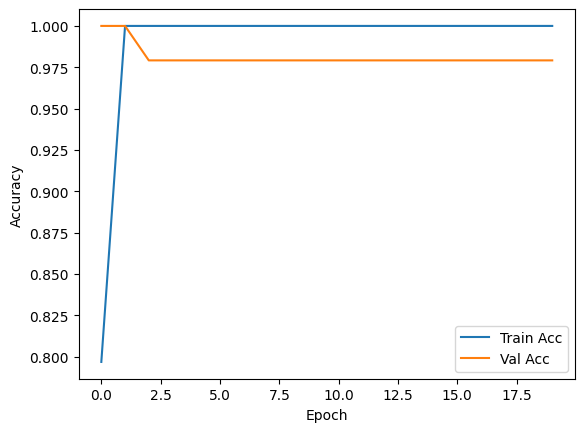

In [13]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## **Langkah 12 - Menyimpan Model dan Scaler (Ekspor Artefak)**

In [15]:
import pickle
import tensorflow as tf

# 1. Konversi Model ke TFLite (Pengganti model.save .h5)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open('day_night_model.tflite', 'wb') as f:
    f.write(tflite_model)
print("✅ Model berhasil dikonversi dan disimpan sebagai: day_night_model.tflite")

# 2. Simpan Scaler (Tetap pakai ini)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: scaler.pkl")

Saved artifact at '/tmp/tmpj5nxb2cr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 34596), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139493632933328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493622351632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493622351248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493622352016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493622351824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139493622351440: TensorSpec(shape=(), dtype=tf.resource, name=None)
✅ Model berhasil dikonversi dan disimpan sebagai: day_night_model.tflite
✅ Scaler berhasil disimpan sebagai: scaler.pkl


---
# **PRAKTIKUM 2 - Deployment Model (Render.com)**

* **Link GitHub Repository:** https://github.com/Mufliha-Hafsyah/daynight-classifier <br>
* **Link Web Deployment:** https://daynight-classifier.onrender.com


*(Catatan: Deployment dilakukan di Render.com sebagai alternatif Hugging Face Spaces yang kini mewajibkan akun PRO berbayar untuk Docker Space. Model juga dikonversi ke TFLite agar ringan dan tidak crash di server gratis).*

**1. Struktur File Project di Laptop**
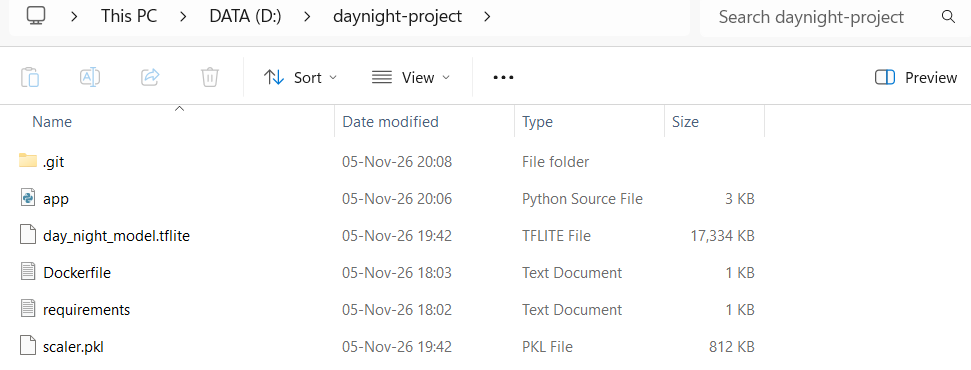

**2. Repository GitHub**
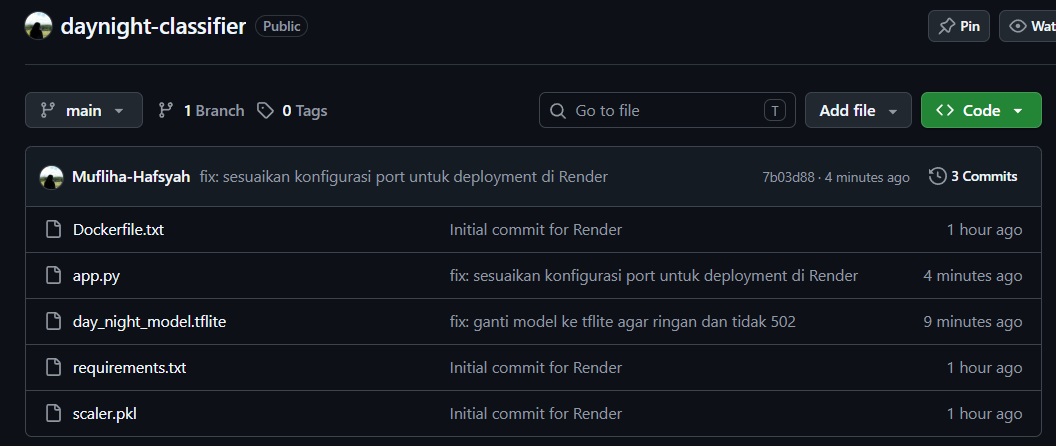

**3. Proses Build di Render.com**
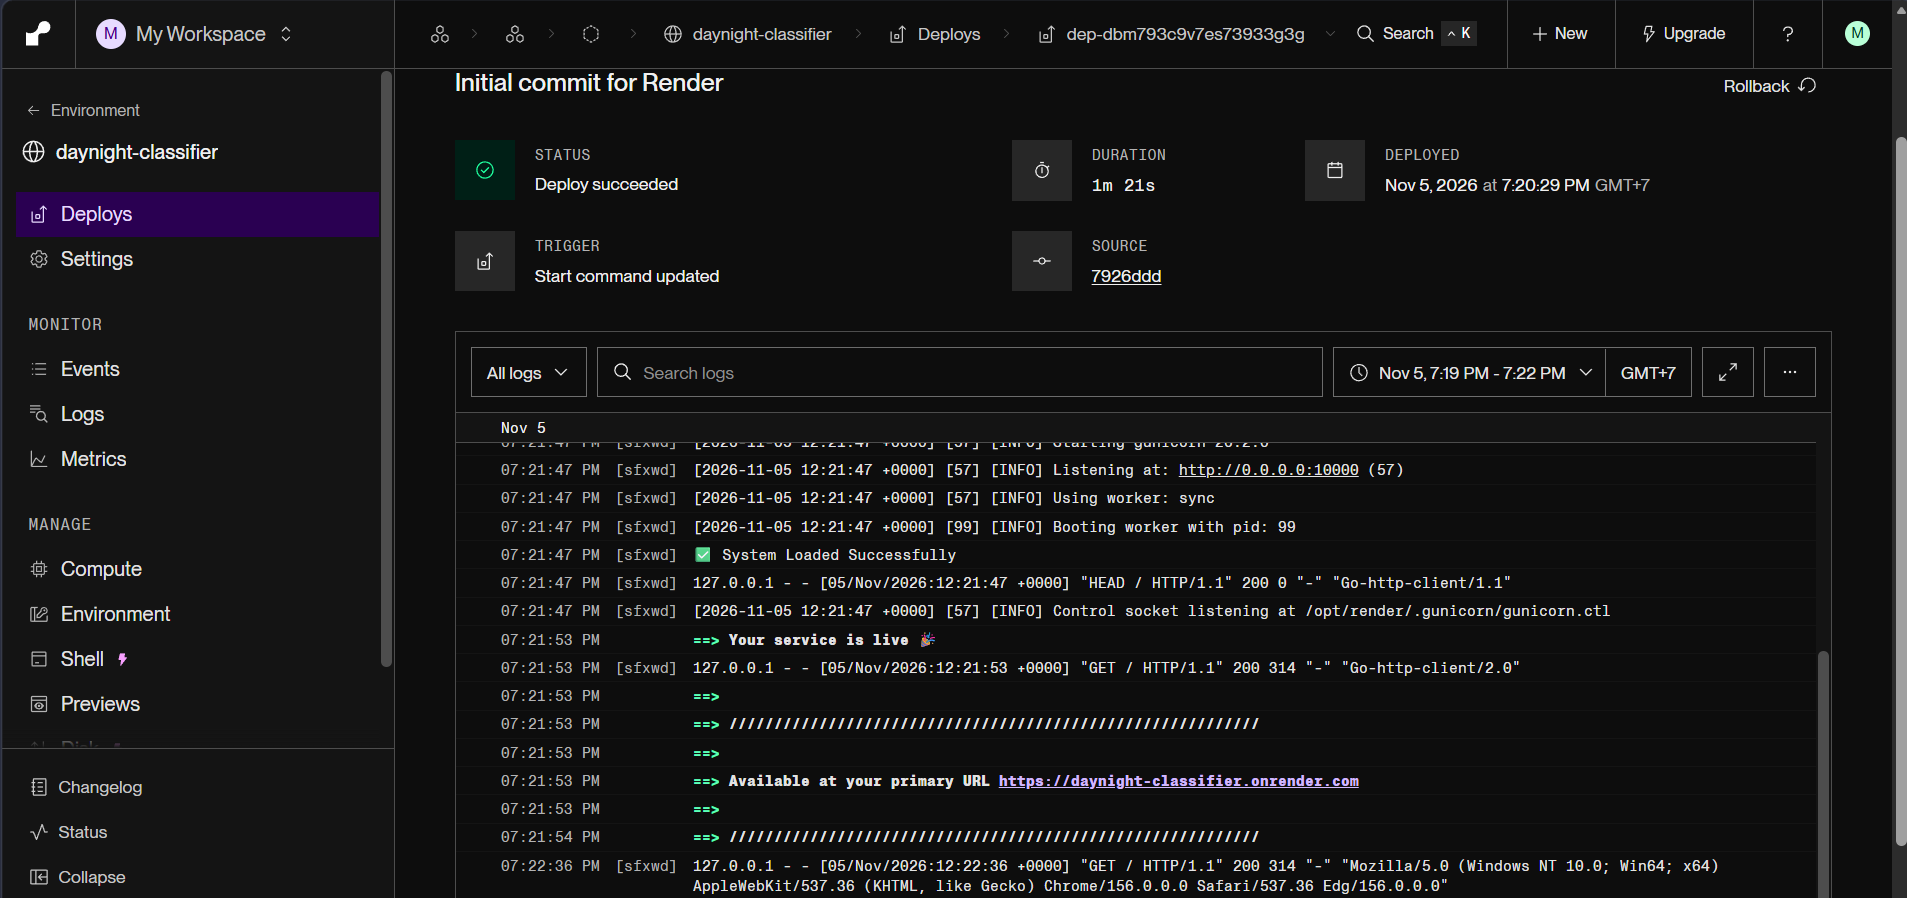

**4. Hasil Pengujian Web**
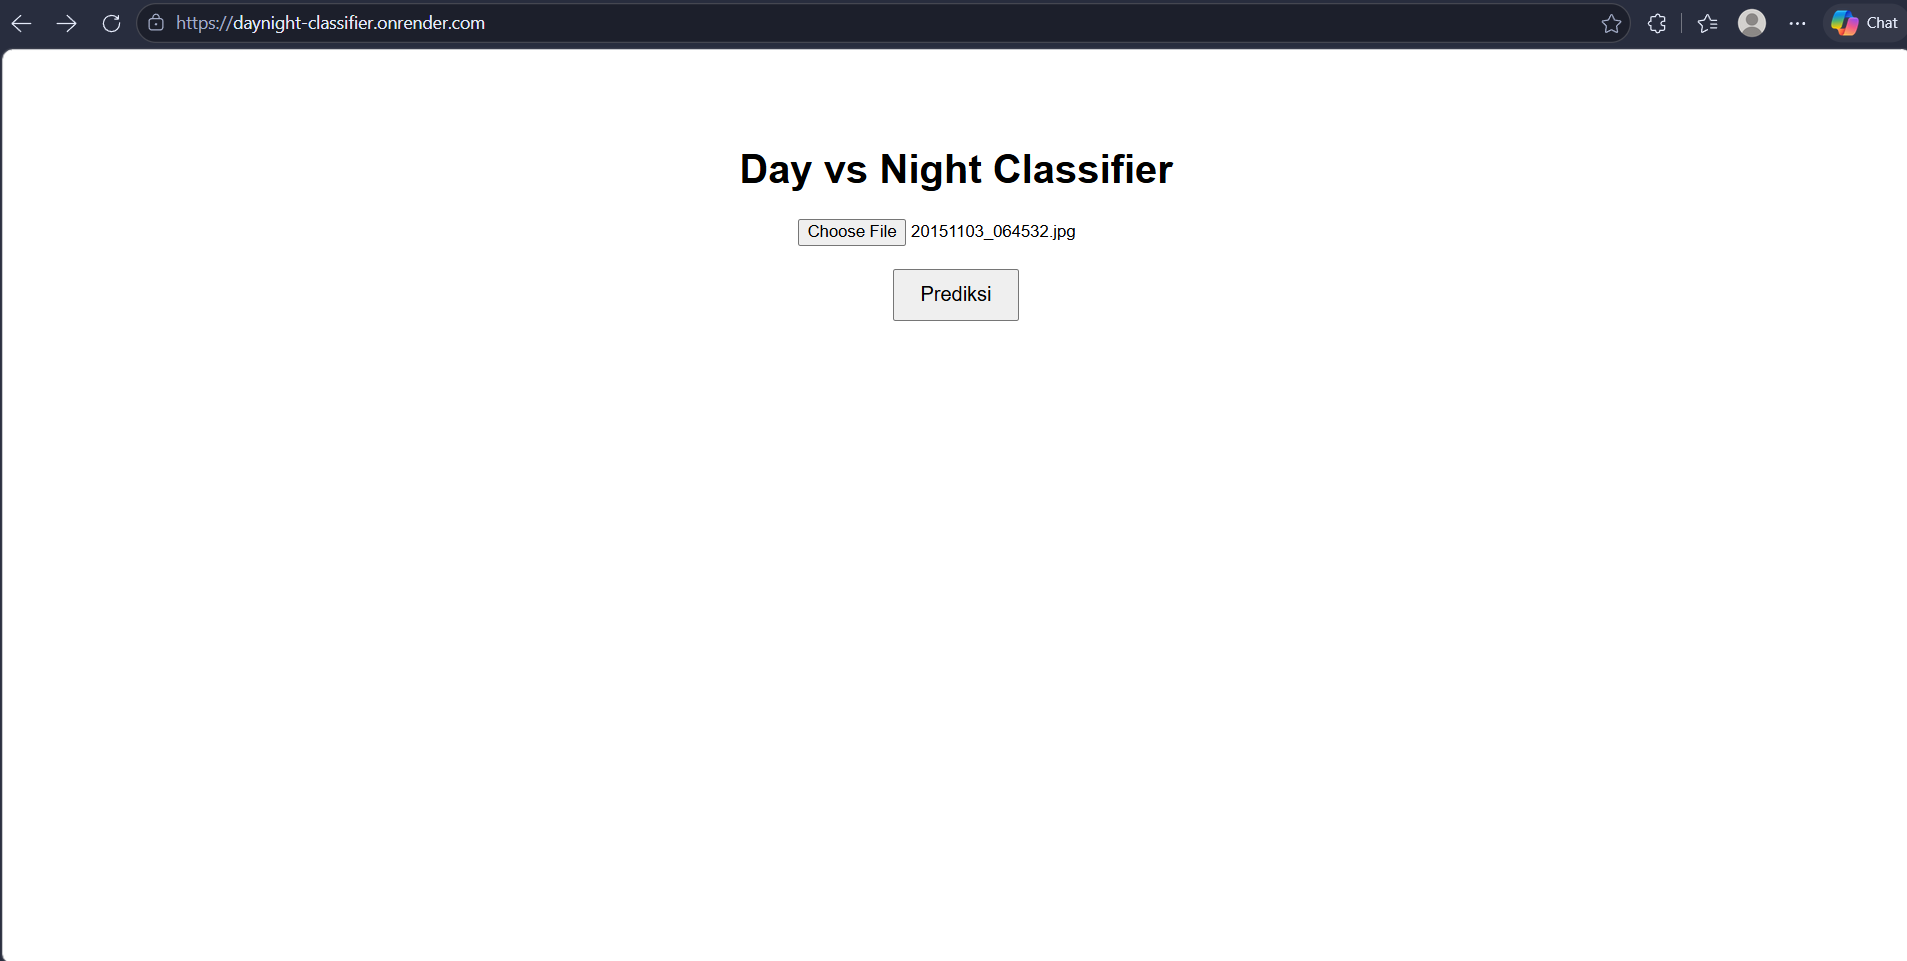
<br>
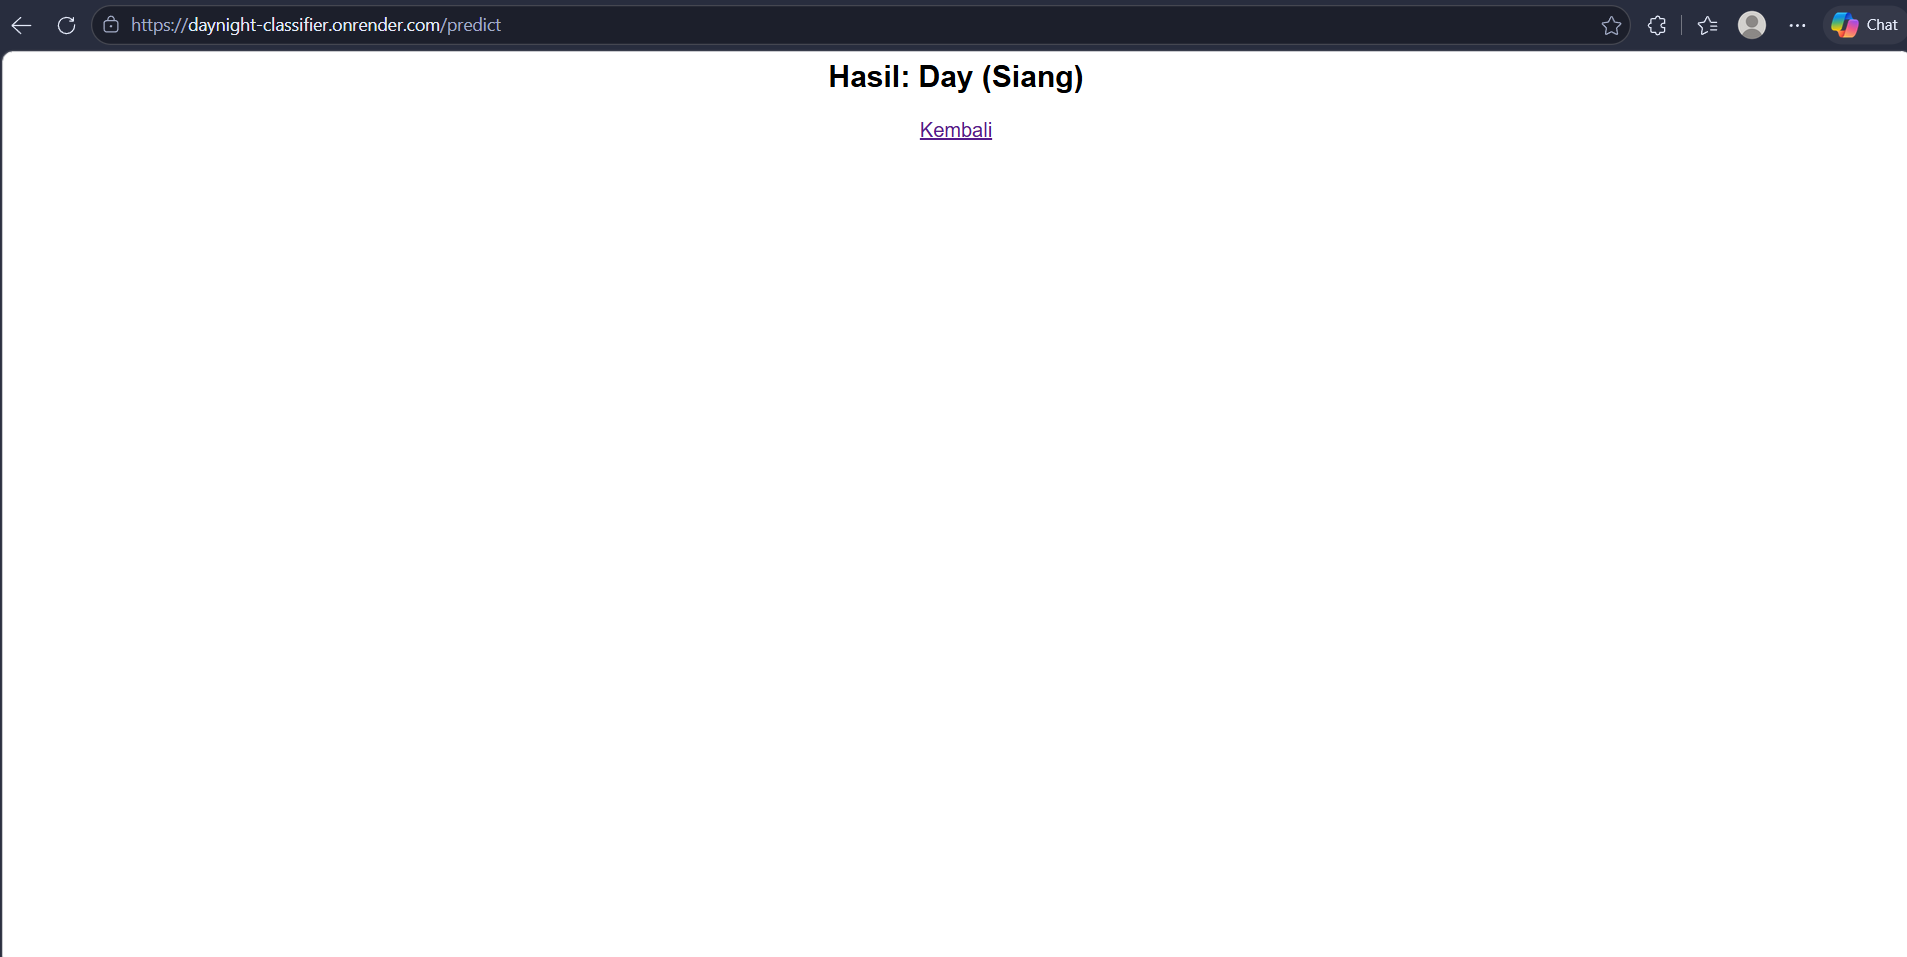